## Análise Exploratória dos Dados
### Rebrickable Lego

O intuito desse notebook é levantar e ponderar algumas questões que surgiram durante um brainstorming enquanto analisávamos os dados disponíveis da empresa Lego, considerando curiosidades, padrões de dados, práticas realizadas, economia, marketing, análise de mercado e afins.

O nosso grupo é composto por: Andrey Fernandes, Gabriel Coelho, Hiago Soares e Pedro Henrique Camilo.

Pra cada bloco de análise especificamente terá a pergunta feita que gerou esses resultados.

**Primeiro é realizado todos os imports das bibliotecas usadas em cada análise.**

In [2]:
import os
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.container import BarContainer

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Configurações de Caminhos
ROOT = Path().resolve().parent
sys.path.insert(0, str(ROOT))

from src.__config__ import PATHS
from src.data_loader import load_all_datasets, load_saved_datasets, save_datasets_as_parquet
from src.spark_session import create_spark_session

DATA_DIR = PATHS.data

# Configurações do Seaborn e Pandas
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Padronização dos Gráficos
plt.rcParams["figure.figsize"] = (10, 6)


**Funções de carregamento de dados e do Spark.**

In [3]:
def load_data() -> dict[str, pd.DataFrame]:
    """Carrega os datasets dos Parquets ou baixa-os quando ainda n?o existem."""
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    has_files = any(path.is_file() for path in DATA_DIR.rglob("*"))

    if has_files:
        print("[Dados] Carregando datasets salvos em Parquet da pasta de dados.")
        dataframes = load_saved_datasets()
        print(f"[Dados] {len(dataframes)} datasets carregados dos Parquets.")
    else:
        print("[Dados] Nenhum dataset encontrado em Parquet. Baixando e salvando datasets.")
        dataframes = load_all_datasets()
        save_datasets_as_parquet(dataframes)
        print(f"[Dados] {len(dataframes)} datasets baixados e salvos.")

    return dataframes


def data_to_rdd(spark: SparkSession):
    """Configura um RDD para cada arquivo Parquet na pasta de dados."""
    rdd_list = {}

    print("[Spark] Configurando RDDs a partir dos arquivos Parquet.")
    for filename in os.listdir(DATA_DIR):
        if filename.endswith(".parquet"):
            name = filename.replace(".parquet", "")
            file_path = DATA_DIR / filename

            try:
                spark_df = spark.read.parquet(str(file_path))
                spark_df.createOrReplaceTempView(name)
                rdd_list[name] = spark_df.rdd
                print(f"[Spark] RDD criado para o arquivo {filename}.")
            except Exception as error:
                print(f"[Erro] Falha ao ler o arquivo Parquet {filename}: {error}")

    print("[Spark] Configuração de RDDs concluída.")
    return rdd_list


**Função de Plotagem.**

In [4]:
def plot_spark(spark_df, kind: str, x: str | None = None, y: str | None = None, hue: str | None = None, title: str | None = None, max_rows: int = 10_000, stacked: bool = False, hue_order: list[str] | None = None, palette: dict | None = None):
    """Gera gráficos Seaborn a partir de um DataFrame do Spark."""
    tipos = {
        "scatter": sns.scatterplot,
        "line": sns.lineplot,
        "bar": sns.barplot,
        "count": sns.countplot,
        "box": sns.boxplot,
        "violin": sns.violinplot,
        "hist": sns.histplot,
        "kde": sns.kdeplot,
    }

    if kind not in tipos:
        raise ValueError(f"Tipo inválido. Escolha entre: {', '.join(tipos)}")

    df = spark_df.limit(max_rows).toPandas()
    colunas = [col for col in (x, y, hue) if col is not None]
    ausentes = [col for col in colunas if col not in df.columns]
    if ausentes:
        raise ValueError(f"Colunas não encontradas: {ausentes}")

    # Para gráficos categóricos usa x como grupo de cores quando hue não for informado
    hue_plot = hue
    if kind in {"bar", "count", "box", "violin"} and hue_plot is None:
        hue_plot = x

    if stacked and (kind != "bar" or x is None or y is None or hue_plot is None):
        raise ValueError("Barras empilhadas exigem kind='bar' e colunas para x, y e hue.")

    categorias = hue_order or (df[hue_plot].dropna().unique().tolist() if hue_plot else [])
    cores = sns.color_palette("mako", n_colors=max(len(categorias), 2))
    palette_plot = palette or (dict(zip(categorias, cores)) if hue_plot else None)

    fig, ax = plt.subplots()

    argumentos = {"data": df, "x": x, "y": y, "ax": ax}
    if hue_plot:
        argumentos.update(hue=hue_plot, palette=palette_plot)
        if hue_order is not None:
            argumentos["hue_order"] = hue_order
    else:
        argumentos["color"] = cores[len(cores) // 2]

    if stacked:
        stacked_data = df.pivot_table(
            index=x,
            columns=hue_plot,
            values=y,
            aggfunc="sum",
            sort=False,
        ).reindex(columns=categorias, fill_value=0).fillna(0)
        bottoms = pd.Series(0.0, index=stacked_data.index)
        for category in categorias:
            if category not in stacked_data.columns:
                continue
            color = palette_plot.get(category) if palette_plot else None
            ax.bar(
                stacked_data.index.astype(str),
                stacked_data[category],
                bottom=bottoms,
                color=color,
                label=category,
                edgecolor="white",
                linewidth=2,
            )
            bottoms += stacked_data[category]
    else:
        if kind in {"bar", "count", "box", "violin"} and hue_plot == x:
            argumentos["dodge"] = False
        tipos[kind](**argumentos)

    # Remove a legenda redundante quando x também é usado pra colorir as categorias
    if hue_plot == x and ax.get_legend() is not None:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()

    if title is not None:
        ax.set_title(title)
        
    fig.tight_layout()
    return ax

**Setup inicial da sessão Spark e criação dos RDDs.**

In [5]:
spark = create_spark_session()
rdds = data_to_rdd(spark)

if not rdds:
    print("[Aviso] Nenhum RDD foi criado. Verifique se os arquivos Parquet estão presentes na pasta de dados.")

[Spark] Configurando RDDs a partir dos arquivos Parquet.
[Spark] RDD criado para o arquivo colors.parquet.
[Spark] RDD criado para o arquivo elements.parquet.
[Spark] RDD criado para o arquivo inventories.parquet.
[Spark] RDD criado para o arquivo inventory_minifigs.parquet.
[Spark] RDD criado para o arquivo inventory_parts.parquet.
[Spark] RDD criado para o arquivo inventory_sets.parquet.
[Spark] RDD criado para o arquivo lego_sets.parquet.
[Spark] RDD criado para o arquivo minifigs.parquet.
[Spark] RDD criado para o arquivo parts.parquet.
[Spark] RDD criado para o arquivo part_categories.parquet.
[Spark] RDD criado para o arquivo part_relationships.parquet.
[Spark] RDD criado para o arquivo sets.parquet.
[Spark] RDD criado para o arquivo themes.parquet.
[Spark] Configuração de RDDs concluída.


## EDA
Agora que já configuramos o notebook para comportar tudo o que será necessário, vamos para as análises abaixo, o que motivou essas análises como as perguntas, e o que se pode perceber com os resultados.

**1) Por acaso a Lego costuma seguir tendências específicas na fabricação de seus sets? Se sim, quais foram os últimos sets mais produzidos por ela?**


[Spark] Tema com mais conjuntos por período:
        1990-1999: Technic (228 conjuntos)
        2000-2009: Bionicle (399 conjuntos)
        2010-2019: Star Wars (515 conjuntos)
        2020-2026: Bags, Totes, & Luggage (695 conjuntos)


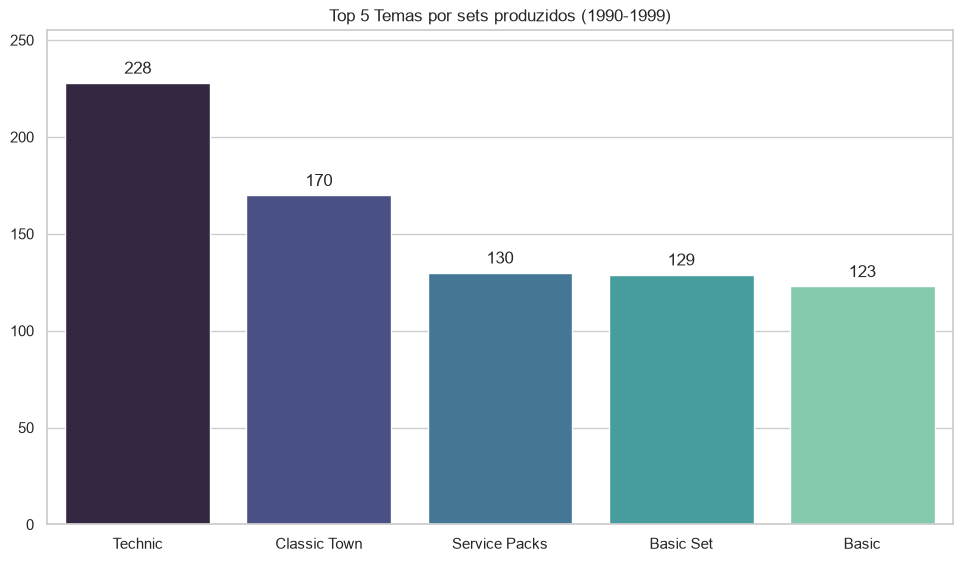

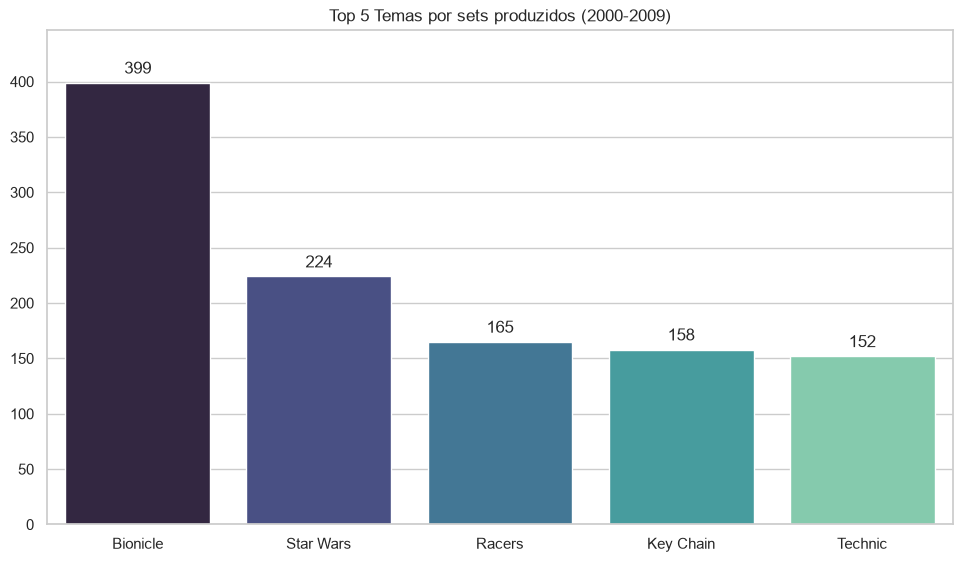

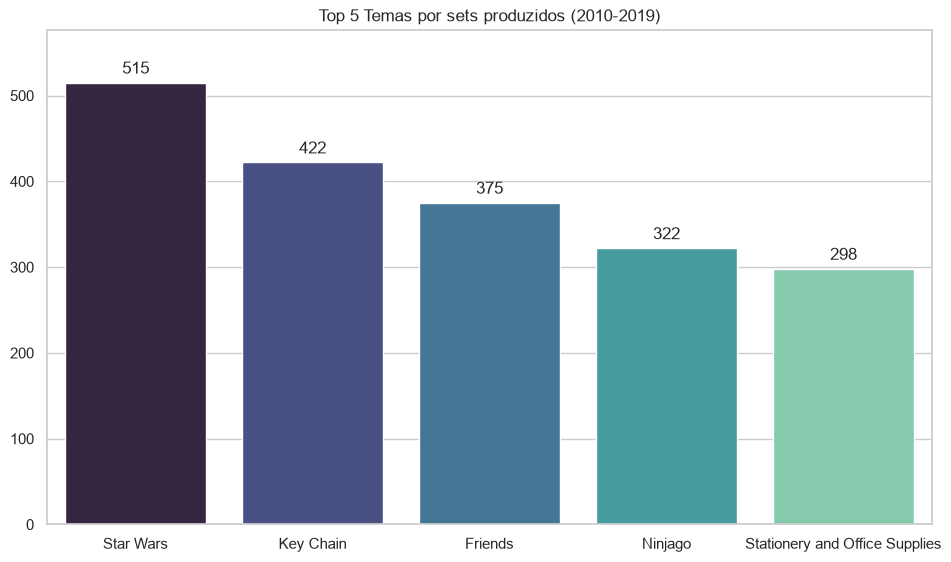

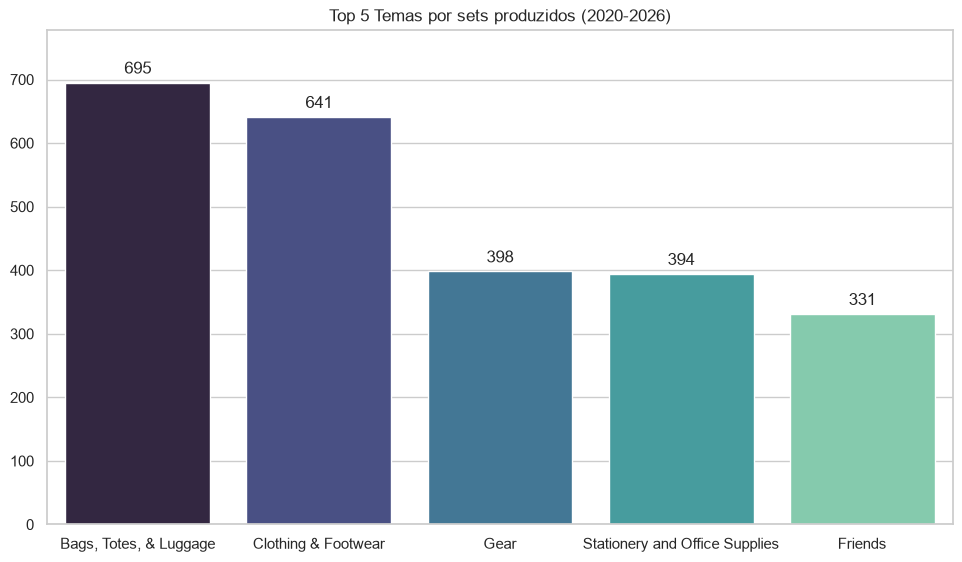

In [6]:
sets = spark.read.parquet(str(DATA_DIR / "sets.parquet")).select("set_num", "year", "theme_id")
themes = spark.read.parquet(str(DATA_DIR / "themes.parquet")).select("id", F.col("name").alias("theme_name"))

dated_sets = sets.filter(F.col("year") > 1989 ).filter(F.col("year") < 2027)
latest_year_row = dated_sets.agg(F.max("year").alias("latest_year")).first()

if latest_year_row is None:
    raise ValueError("Não há conjuntos com ano de lançamento a partir de 1989.")

latest_year = latest_year_row["latest_year"]

period_start = (F.floor((F.col("year") - F.lit(1990)) / F.lit(10)) * F.lit(10)+ F.lit(1990))
theme_counts = (
    dated_sets.join(themes, dated_sets.theme_id == themes.id, "left")
    .withColumn("theme_name", F.coalesce(F.col("theme_name"), F.lit("Tema não identificado")))
    .withColumn("period_start", period_start.cast("int"))
    .withColumn("period_end", F.least(F.col("period_start") + F.lit(9), F.lit(int(latest_year))))
    .withColumn("period", F.concat_ws("-", F.col("period_start").cast("string"), F.col("period_end").cast("string")))
    .groupBy("period", "theme_name")
    .agg(F.count_distinct("set_num").alias("sets_produced"))
)

ranking = Window.partitionBy("period").orderBy(F.desc("sets_produced"), F.asc("theme_name"))

top_themes = (theme_counts.withColumn("rank", F.row_number().over(ranking)) .filter(F.col("rank") <= 5) .orderBy("period", F.col("rank")) .toPandas())
periods = top_themes["period"].drop_duplicates().tolist()

print("\n[Spark] Tema com mais conjuntos por período:")
for period in periods:
    leader = top_themes.loc[top_themes["period"] == period].iloc[0]
    print(f"        {period}: {leader['theme_name']} ({leader['sets_produced']} conjuntos)")

for period in periods:
    period_top = (theme_counts.filter(F.col("period") == period).orderBy(F.desc("sets_produced"), F.asc("theme_name")).limit(5))

    ax = plot_spark(period_top, kind="bar", x="theme_name", y="sets_produced", title=f"Top 5 Temas por sets produzidos ({period})")
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.margins(y=0.12)

    for container in ax.containers:
        if isinstance(container, BarContainer):
            ax.bar_label(container, fmt="%.0f", padding=4)

Após a análise acima, podemos considerar os resultados **parciais**. E qual seria o motivo pra isso?

Existem apenas dois períodos que de fato seguem alguma tendência popular, são eles 2000 até 2009 e principalmente 2010 até 2019. Ambos os períodos seguem tendências populares de mídias que já estavam ficando famosas ou *brands* criadas a partir de um tema visual, como caso do Bionicle, além da presença de Ninjago e Racers. O período de 1990 adiante seguem sets mais amplos e genéricos, como construções, partes básicas, com uma única ressalva de uma tendência para carros especificamente com a linha Technic.

De resto, é curioso notar que mesmo em um mundo que se tornou bem mais globalizado com amplo acesso a internet para milhões de usuários e crianças desde cedo, a Lego deixou de seguir tendências e voltou sua atenção na criação de sets mais genéricos porém amplos, que não seguem deliberadamente um tema ou estilo específico.

Porém, sendo assim, se a tendência deixou de ser específica nos anos atuais da lego, como que os sets de mídias famosas como Star Wars, Minecraft e afins continuam tão popular? É daí que pensamos na próxima pergunta.

**2) Quais foram os principais temas mais investidos pela Lego na produção de partes e materiais?**


[Spark] Temas gerais com mais peças contabilizadas (1990-2026):
        Star Wars: 426,762 peças
        Technic: 305,409 peças
        Creator: 235,208 peças
        City: 228,217 peças
        Ninjago: 191,567 peças
        Icons: 181,255 peças
        Friends: 166,980 peças
        Educational and Dacta: 162,596 peças
        BrickLink Designer Program: 134,937 peças
        Super Heroes Marvel: 132,269 peças

[Spark] Tema geral com mais peças por período:
        1990-1999: Town (40,606 peças)
        2000-2009: Star Wars (87,916 peças)
        2010-2019: Star Wars (168,037 peças)
        2020-2026: Icons (181,255 peças)


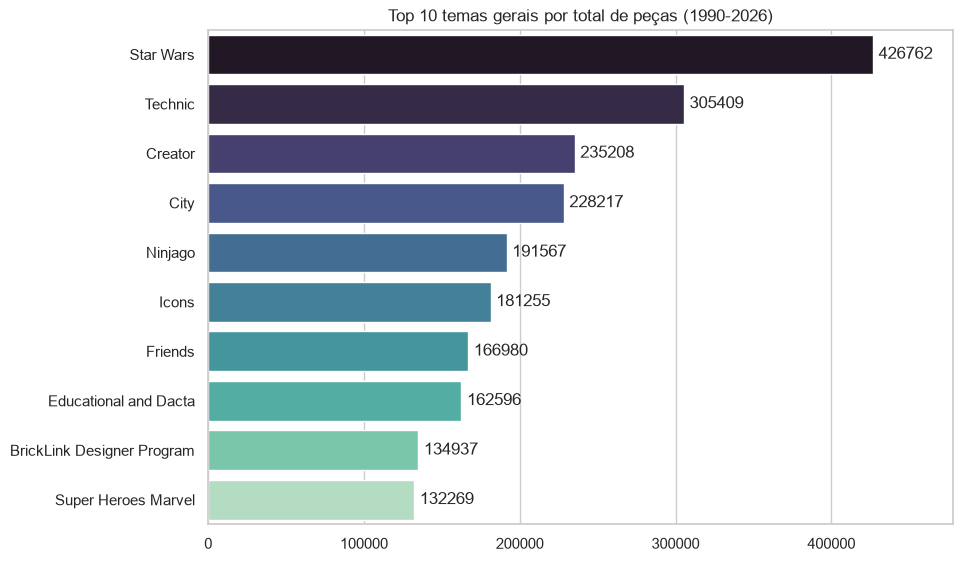

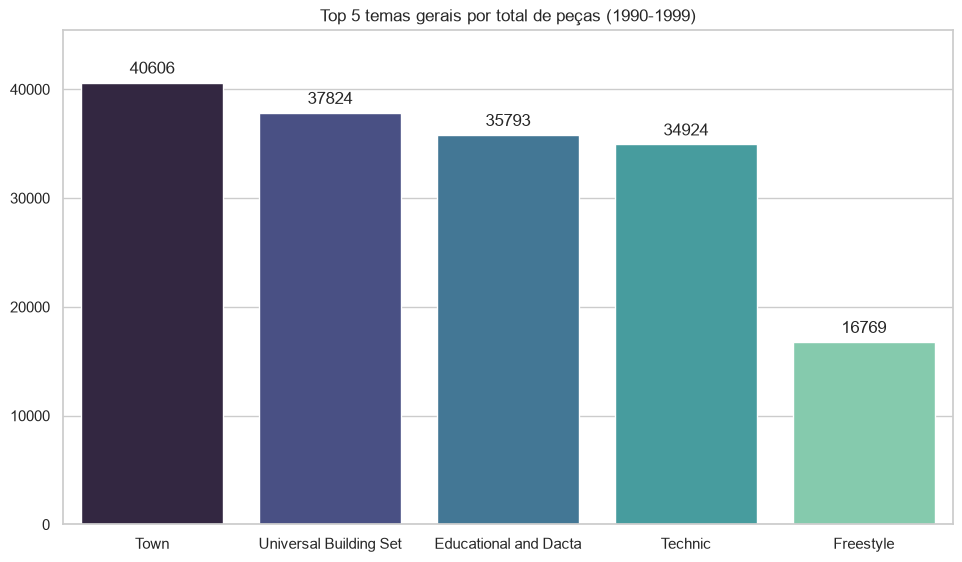

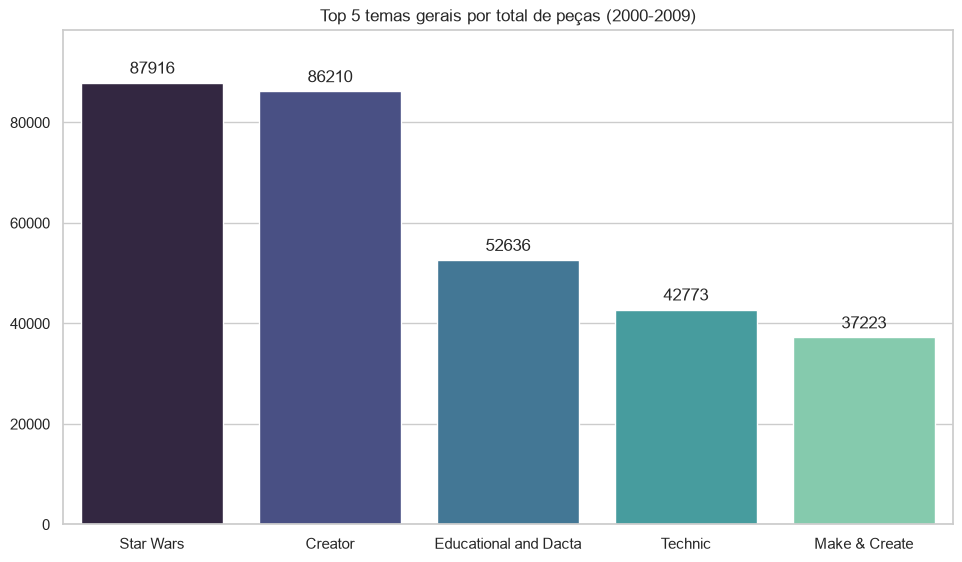

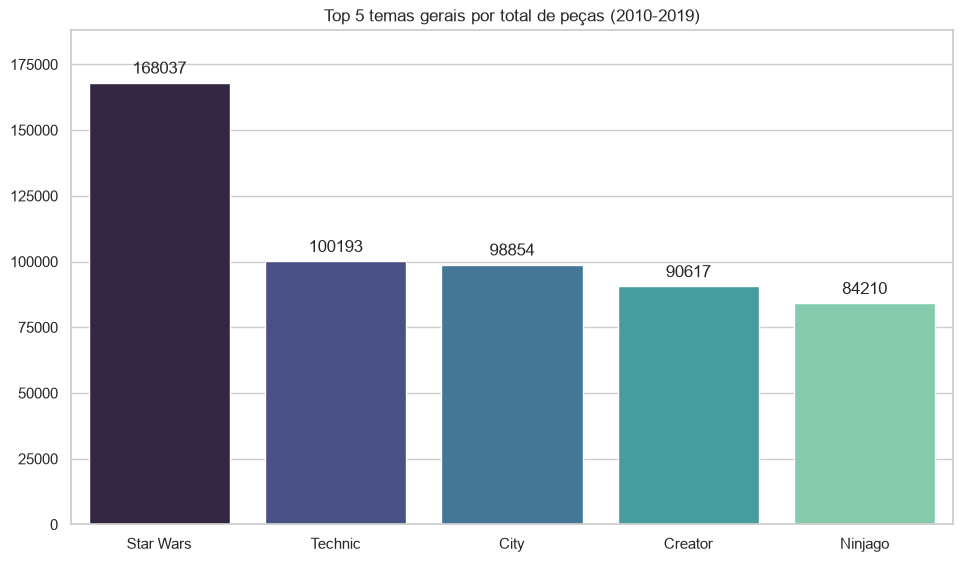

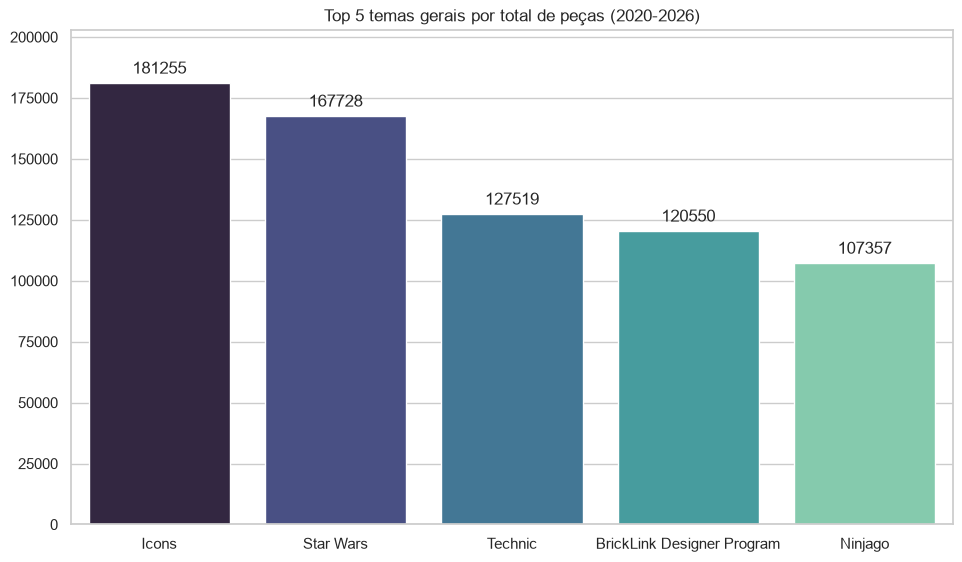

In [7]:
sets = (
    spark.read.parquet(str(DATA_DIR / "sets.parquet"))
    .filter(F.col("year").between(1990, 2026))
    .select("set_num", "year", "theme_id", "num_parts")
)

themes = spark.read.parquet(str(DATA_DIR / "themes.parquet")).select("id", "name", "parent_id")

latest_year_row = sets.agg(F.max("year").alias("latest_year")).first()
if latest_year_row is None:
    raise ValueError("Não há conjuntos entre 1990 e 2026 para analisar.")
    
latest_year = latest_year_row["latest_year"]
if latest_year is None:
    raise ValueError("Não há conjuntos entre 1990 e 2026 para analisar.")

theme_hierarchy = themes.select(F.col("id").alias("theme_id"), F.col("name").alias("general_theme"), F.col("parent_id").alias("next_parent_id"))

for _ in range(themes.count() + 1):
    unresolved = theme_hierarchy.filter(F.col("next_parent_id").isNotNull())
    if unresolved.limit(1).count() == 0:
        break

    parent_themes = themes.alias("parent")
    expanded = unresolved.alias("child").join(parent_themes, F.col("child.next_parent_id") == F.col("parent.id"), "left")
    
    if expanded.filter(F.col("parent.id").isNull()).limit(1).count():
        raise ValueError("A hierarquia de temas contém um tema pai inexistente.")

    theme_hierarchy = theme_hierarchy.filter(
        F.col("next_parent_id").isNull()
        ).unionByName(expanded.select(
            F.col("child.theme_id").alias("theme_id"),
            F.col("parent.name").alias("general_theme"),
            F.col("parent.parent_id").alias("next_parent_id"),
        )
    )
else:
    raise ValueError("A hierarquia de temas contém um ciclo.")

sets_with_general_theme = (
    sets.join(theme_hierarchy.select("theme_id", "general_theme"), "theme_id", "left")
    .withColumn(
        "general_theme",
        F.coalesce(F.col("general_theme"), F.lit("Tema não identificado")),
    )
)

period_start = F.floor((F.col("year") - F.lit(1990)) / F.lit(10)) * F.lit(10) + F.lit(1990)

sets_with_period = (
    sets_with_general_theme.withColumn("period_start", period_start.cast("int"))
    .withColumn(
        "period_end",
        F.least(F.col("period_start") + F.lit(9), F.lit(int(latest_year))),
    ).withColumn(
        "period",
        F.concat_ws("-", F.col("period_start").cast("string"), F.col("period_end").cast("string")),
    )
)

overall_totals = sets_with_general_theme.groupBy("general_theme").agg(
    F.sum("num_parts").alias("total_parts")
)
overall_top = (
    overall_totals.orderBy(F.desc("total_parts"), F.asc("general_theme"))
    .limit(10)
    .toPandas()
)

period_totals = sets_with_period.groupBy("period", "general_theme").agg(F.sum("num_parts").alias("total_parts"))
ranking = Window.partitionBy("period").orderBy(F.desc("total_parts"), F.asc("general_theme"))

period_top = (
    period_totals.withColumn("rank", F.row_number().over(ranking))
    .filter(F.col("rank") <= 5)
    .orderBy("period", F.col("rank"))
    .toPandas()
)

periods = period_top["period"].drop_duplicates().tolist()

print("\n[Spark] Temas gerais com mais peças contabilizadas (1990-2026):")
for _, theme in overall_top.iterrows():
    print(f"        {theme['general_theme']}: {theme['total_parts']:,.0f} peças")

overall_plot_data = overall_totals.orderBy(F.desc("total_parts"), F.asc("general_theme")).limit(10)

overall_ax = plot_spark(overall_plot_data, kind="bar", x="total_parts", y="general_theme", hue="general_theme", title="Top 10 temas gerais por total de peças (1990-2026)")

overall_ax.set_xlabel("")
overall_ax.set_ylabel("")
overall_ax.margins(x=0.12)

for container in overall_ax.containers:
    if isinstance(container, BarContainer):
        overall_ax.bar_label(container, fmt="%.0f", padding=4)

print("\n[Spark] Tema geral com mais peças por período:")
for period in periods:
    leader = period_top.loc[period_top["period"] == period].iloc[0]
    print(f"        {period}: {leader['general_theme']} ({leader['total_parts']:,.0f} peças)")

    period_plot_data = (period_totals.filter(F.col("period") == period).orderBy(F.desc("total_parts"), F.asc("general_theme")).limit(5))

    period_ax = plot_spark(period_plot_data, kind="bar", x="general_theme", y="total_parts", hue="general_theme", title=f"Top 5 temas gerais por total de peças ({period})")

    period_ax.set_xlabel("")
    period_ax.set_ylabel("")
    period_ax.margins(y=0.12)

    for container in period_ax.containers:
        if isinstance(container, BarContainer):
            period_ax.bar_label(container, fmt="%.0f", padding=4)

Analisando primeiro o comparativo do total de peças fabricadas por tema dentre 1990 e 2026, é possível notar a clara dominância de Star Wars seguido logo pela linha Technic. É com base nisso que podemos validar o nosso último questionamento, mesmo que a Lego não tenha uma clara tendência popular sendo seguida em algum período, não quer dizer que as últimas tendências, ou até mesmo alguma tendência que ainda continua popular não esteja sendo investida.

Há uma clara dominância nos números gerais entre os últimos 35 anos pertencentes a Star Wars, que é sem sombra de dúvidas a maior linha de produtos da Lego, e, analisando agora os outros gráficos por período tudo isso começou exatamente entre os anos 2000, quando se popularizou essa mídia. Logo, até mesmo no último período de 2020 até 2026, apesar de Star Wars não ter sido a linha mais produzida, ainda se encontra entre o segundo mais produzido, logo à frente de Technic e também Ninjago, duas tendências que continuam ainda bem populares.

#### Análise do set LEGO Legends of Chima
Saindo um pouco das análises gerais, vamos nos aprofundar em um tema específico como o Legends of Chima. O motivo dessa análise se dá pela grande quantidade de peças que pertencem a esse conjunto encontrados na nossa base de dados, atrás apenas do World Map e Eiffel Tower. Além disso, o conjunto também está entre os conjuntos que mais possuem minifigures disponíveis.

**Como um teste inicial, conferimos se ele está registrado na tabela "themes".**

In [8]:
query_temas_chima = """
SELECT
    id,
    name,
    parent_id
FROM themes
WHERE name LIKE '%Chima%'
ORDER BY name
"""

spark.sql(query_temas_chima).show(50, truncate=False)

+---+----------------+---------+
|id |name            |parent_id|
+---+----------------+---------+
|571|Legends of Chima|NULL     |
+---+----------------+---------+



A consulta identificou o tema **Legends of Chima** com sucesso, seu id sendo `571`.

Com o id em mãos, podemos filtrar os conjuntos associados diretamente ao tema por meio da coluna theme_id da tabela sets, permitindo concentrar as próximas análises nos conjuntos classificados como Legends of Chima.

**Agora, buscaremos as figures de alguns personagens mais recorrentes.**

In [9]:
query_personagens_chima = """
WITH minifigs_chima AS (
    SELECT DISTINCT
        s.set_num,
        m.fig_num,
        m.name AS minifig_name
    FROM sets s
    JOIN inventories i
        ON s.set_num = i.set_num
    JOIN inventory_minifigs im
        ON i.id = im.inventory_id
    JOIN minifigs m
        ON im.fig_num = m.fig_num
    WHERE s.theme_id = 571
),

personagens AS (
    SELECT
        set_num,
        fig_num,
        CASE
            WHEN name_base LIKE '%Laval%' THEN 'Laval'
            WHEN name_base LIKE '%Cragger%' THEN 'Cragger'
            ELSE name_base
        END AS personagem
    FROM (
        SELECT
            set_num,
            fig_num,
            TRIM(
                REGEXP_REPLACE(
                    minifig_name,
                    '( with .*| in .*|,.*| [(].*[)])$',
                    ''
                )
            ) AS name_base
        FROM minifigs_chima
    )
)

SELECT
    personagem,
    COUNT(DISTINCT set_num) AS total_sets
FROM personagens
GROUP BY personagem
ORDER BY total_sets DESC, personagem ASC
LIMIT 30
"""

resultado_personagens_chima = spark.sql(query_personagens_chima)
resultado_personagens_chima.show(30, truncate=False)

resultado_personagens_chima = spark.sql(query_personagens_chima)
resultado_personagens_chima.show(30, truncate=False)

+----------+----------+
|personagem|total_sets|
+----------+----------+
|Worriz    |10        |
|Cragger   |9         |
|Gorzan    |9         |
|Eris      |8         |
|Laval     |8         |
|Razar     |6         |
|Strainor  |6         |
|Vornon    |6         |
|Crug      |5         |
|Lennox    |5         |
|Razcal    |5         |
|Stealthor |5         |
|Sykor     |5         |
|Crawley   |4         |
|Crominus  |4         |
|Ewar      |4         |
|Frax      |4         |
|Iceklaw   |4         |
|Leonidas  |4         |
|Rogon     |4         |
|Sir Fangar|4         |
|Vardy     |4         |
|Voom Voom |4         |
|Bulkar    |3         |
|Flinx     |3         |
|Grumlo    |3         |
|Icepaw    |3         |
|Lagravis  |3         |
|Li'Ella   |3         |
|Longtooth |3         |
+----------+----------+

+----------+----------+
|personagem|total_sets|
+----------+----------+
|Worriz    |10        |
|Cragger   |9         |
|Gorzan    |9         |
|Eris      |8         |
|Laval     |8  

Com um contexto básico da série temática, é interessante notar que os três primeiros colocados aparecem logo na frente do protagonista principal, Laval, mostrando que a recorrência de uma minifigure em um conjunto não exatamente coincide com a importância narrativa atribuída a um personagem. Porém, isso também não significa que esses personagens sejam ou não sejam populares, melhor tratar apenas como uma simples curiosidade de produção.

**Com o foco em Laval, vamos analisar quais sets contém as figures dele, assim como quais personagens que mais o acompanham.**

+--------+-----------------------------+----+--------------------------------------+
|set_num |set_name                     |year|minifig_name                          |
+--------+-----------------------------+----+--------------------------------------+
|70005-1 |Laval's Royal Fighter        |2013|Laval with Shoulder Armor and Cape    |
|70010-1 |The Lion CHI Temple          |2013|Laval with Shoulder Armor and Cape    |
|70115-1 |Ultimate Speedor Tournament  |2013|Laval with Shoulder Armor and Cape    |
|70156-1 |Fire vs. Ice                 |2014|Laval in Fire Chi Outfit              |
|70144-1 |Laval's Fire Lion            |2014|Laval with Shoulder Armor and Fire Chi|
|70134-1 |Lavertus' Outland Base       |2014|Laval in Shoulder Armor               |
|70123-1 |Lion Legend Beast            |2014|Laval                                 |
|70132-1 |Scorm's Scorpion Stinger     |2014|Laval in Shoulder Armor               |
|70227-1 |King Crominus' Rescue        |2015|Laval with Flame Win

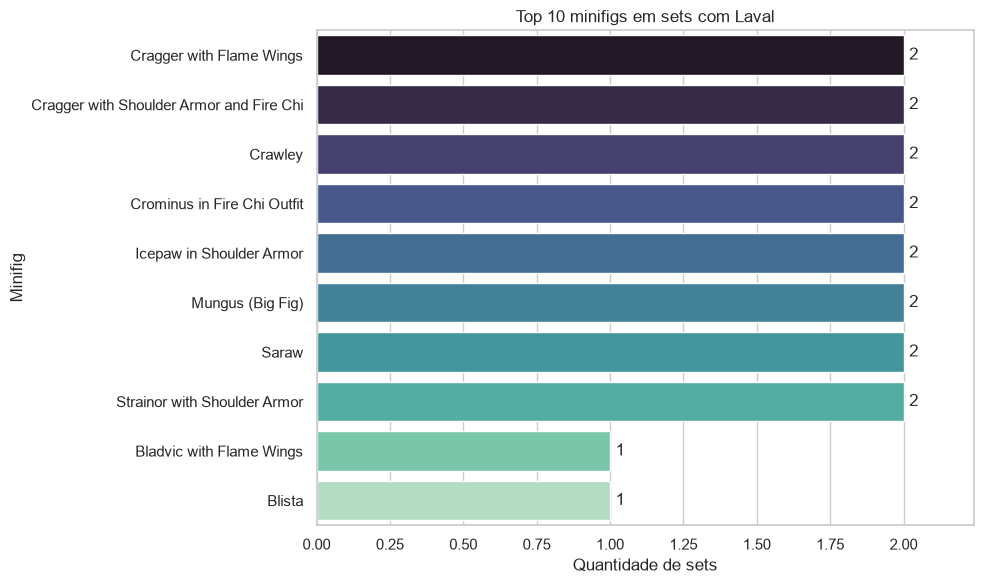

In [10]:
query_laval_sets = """
SELECT DISTINCT
    s.set_num,
    s.name AS set_name,
    s.year,
    m.name AS minifig_name
FROM sets s
JOIN inventories i
    ON s.set_num = i.set_num
JOIN inventory_minifigs im
    ON i.id = im.inventory_id
JOIN minifigs m
    ON im.fig_num = m.fig_num
WHERE m.name LIKE '%Laval%'
ORDER BY year, set_name
"""

results_laval_sets = spark.sql(query_laval_sets)
results_laval_sets.show(50, truncate=False)

query_laval_sets_count = """
SELECT
    COUNT(DISTINCT s.set_num) AS total_sets_com_laval
FROM sets s
JOIN inventories i
    ON s.set_num = i.set_num
JOIN inventory_minifigs im
    ON i.id = im.inventory_id
JOIN minifigs m
    ON im.fig_num = m.fig_num
WHERE m.name LIKE '%Laval%'
"""

results_laval_sets_count = spark.sql(query_laval_sets_count)
results_laval_sets_count.show()

query_figures_with_laval = """
WITH sets_com_laval AS (
    SELECT DISTINCT
        s.set_num
    FROM sets s
    JOIN inventories i
        ON s.set_num = i.set_num
    JOIN inventory_minifigs im
        ON i.id = im.inventory_id
    JOIN minifigs m
        ON im.fig_num = m.fig_num
    WHERE m.name LIKE '%Laval%'
)

SELECT
    m.fig_num,
    m.name AS minifig_name,
    COUNT(DISTINCT s.set_num) AS total_sets
FROM sets s
JOIN inventories i
    ON s.set_num = i.set_num
JOIN inventory_minifigs im
    ON i.id = im.inventory_id
JOIN minifigs m
    ON im.fig_num = m.fig_num
JOIN sets_com_laval sl
    ON s.set_num = sl.set_num
WHERE m.name NOT LIKE '%Laval%'
GROUP BY
    m.fig_num,
    m.name
ORDER BY
    total_sets DESC,
    minifig_name
LIMIT 10
"""

results_figures_with_laval = spark.sql(query_figures_with_laval)

# Armazenar e ordenar os resultados do Spark para a plotagem.
figures_with_laval_ordered = results_figures_with_laval.orderBy(F.desc("total_sets"), F.asc("minifig_name"))

figures_with_laval_ax = plot_spark(figures_with_laval_ordered, kind="bar", x="total_sets", y="minifig_name", hue="minifig_name", title="Top 10 minifigs em sets com Laval")

figures_with_laval_ax.set_xlabel("Quantidade de sets")
figures_with_laval_ax.set_ylabel("Minifig")
figures_with_laval_ax.margins(x=0.12)

for container in figures_with_laval_ax.containers:
    if isinstance(container, BarContainer):
        figures_with_laval_ax.bar_label(container, fmt="%.0f", padding=4)
    



Porém, como cada versão de uma minifigure é contabilizada separadamente, a frequência total de um personagem pode estar distribuída entre diferentes registros ao todo. Por fim, esses conjuntos estão distribuídos igualmente entre os anos 2013 a 2015, com dois conjuntos identificados em cada ano especificamente. Uma curiosidade para se notar é que, alguns dizem que o conjunto de Legends of Chima acompanha uma continuação indireta do mundo de Ninjago, apesar de ambos serem mídias diferentes, o universo dos dois é compartilhado entre si, até com alguns *crossovers* oficiais da LEGO.

### Análise de Peças em Conjuntos
Voltando para o contexto de uma análise central entre os diversos conjuntos de temas da Lego, após a análise específica do conjunto Legends of Chima, pudemos notar que há uma imensidão de todo e qualquer tipo de conjuntos fabricados pela Lego. Entre os temas desses conjuntos, é claro que há os de mídias famosas como Star Wars, DC e Marvel e Senhor dos Anéis; temas especializados em assuntos específicos como Technic, sobre carros; mídias propriamente desenvolvidas pela Lego como Ninjago, Racers, Lego City, Friends; além de outros temas gerais como Construções, Cidades Medievais, Agricultura e por ai vai.

Após ponderarmos nesse assunto e pensar em talvez qual seria o próximo tema que deveríamos abordar, acabamos chegando a um questionamento que parte de um princípio bem básico porém intrigante:

**4) Existe um conjunto de peças que aparece em quase todos os temas?**

+--------+--------------------------------------+------------+----------+
|part_num|part_name                             |total_themes|percentual|
+--------+--------------------------------------+------------+----------+
|3022    |Plate 2 x 2                           |345         |69.56     |
|3023    |Plate 1 x 2                           |341         |68.75     |
|3020    |Plate 2 x 4                           |336         |67.74     |
|3004    |Brick 1 x 2                           |330         |66.53     |
|3021    |Plate 2 x 3                           |325         |65.52     |
|3710    |Plate 1 x 4                           |324         |65.32     |
|3010    |Brick 1 x 4                           |319         |64.31     |
|3039    |Brick Sloped 45° 2 x 2                |315         |63.51     |
|6141    |Plate Round 1 x 1 with Solid Stud     |315         |63.51     |
|3005    |Brick 1 x 1                           |307         |61.9      |
|3062b   |Brick Round 1 x 1 Open Stud 

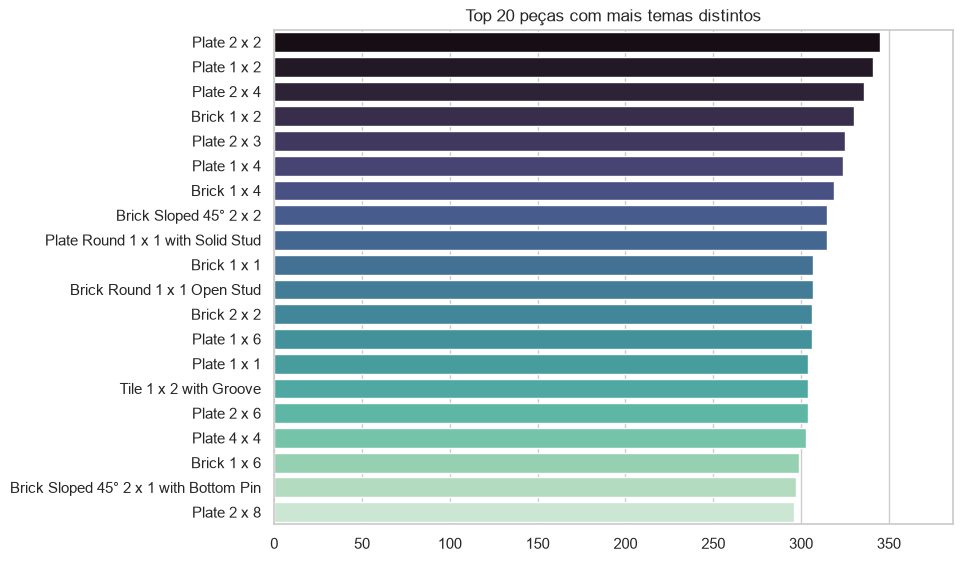

In [11]:
inventory_parts_df = spark.table("inventory_parts").alias("inv_p")
inventories_df = spark.table("inventories").alias("inv")
sets_df = spark.table("sets").alias("sets")
themes_df = spark.table("themes").alias("themes")
parts_df = spark.table("parts").alias("parts")

# Mantem uma linha por peça, conjunto e tema para permitir outras analises depois.
parts_themes = (
    inventory_parts_df
    .join(inventories_df, F.col("inv_p.inventory_id") == F.col("inv.id"), "inner")
    .join(sets_df, F.col("inv.set_num") == F.col("sets.set_num"), "inner")
    .join(themes_df, F.col("sets.theme_id") == F.col("themes.id"), "inner")
    .join(parts_df, F.col("inv_p.part_num") == F.col("parts.part_num"), "left")
    .select(
        F.col("inv_p.part_num").alias("part_num"),
        F.col("parts.name").alias("part_name"),
        F.col("inv.set_num").alias("set_num"),
        F.col("themes.id").alias("theme_id"),
        F.col("themes.name").alias("theme_name"),
    )
    .dropDuplicates(["part_num", "set_num", "theme_id"])
)

# Conta cada tema uma vez por peca, mesmo quando ela aparece em varios sets do mesmo tema.
themes_per_part = (parts_themes.groupBy("part_num", "part_name").agg(F.count_distinct("theme_id").alias("total_themes")))

# Fazer percentual com base no total de temas distintos
total_distinct_themes = themes_df.count()
themes_per_part = themes_per_part.withColumn("percentual", F.round((F.col("total_themes") / F.lit(total_distinct_themes)) * 100, 2))

parts_with_most_themes = themes_per_part.orderBy(F.desc("total_themes"), F.asc("part_num"))

parts_with_most_themes.show(20, truncate=False)

# Plotando o gráfico de barras para as peças com mais temas distintos
parts_with_most_themes_ax = plot_spark(parts_with_most_themes.limit(20), kind="bar", x="total_themes", y="part_name", hue="part_name", title="Top 20 peças com mais temas distintos")

parts_with_most_themes_ax.set_xlabel("")
parts_with_most_themes_ax.set_ylabel("")
parts_with_most_themes_ax.margins(x=0.12)



Com base nesses insights vemos que há sim peças que são realmente muito reutilizadas dentre todos os temas da Lego. As peças mais comuns encontradas foram a 3022 e 3022 respectivamente, com uma fazendo parte de até `345` temas distintos, enquanto a outra `341`. Isso também pode ser um bom indicador de que a Lego tem o costume de reutilizar formatos de peças durante a fabricação para diversos tipos de conjuntos, assim é possível poupar mais gastos com peças de fácil fabricação e de grande utilidade geral, seria isso um *possível* indicador do próprio sucesso da Lego? Da reutilização de moldes?

Imagens das peças `3022` e `3023` em sequência.

![Peca 3022](https://cdn.rebrickable.com/media/thumbs/parts/elements/302226.jpg/250x250p.jpg?1778377693.8467324)
![Peca 3023](https://cdn.rebrickable.com/media/thumbs/parts/elements/302326.jpg/250x250p.jpg?1778380785.9816208)

Por fim, enquanto explorávamos esse questionamento também havia surgido outro que o complementa:

**5) Quais foram os conjuntos de temas que mais geraram peças exclusivas?**

+------------------------------+--------------------+-------------------------+
|theme_name                    |exclusive_part_types|sets_with_exclusive_parts|
+------------------------------+--------------------+-------------------------+
|Star Wars                     |905                 |480                      |
|Technic                       |851                 |355                      |
|Friends                       |840                 |426                      |
|Ninjago                       |819                 |323                      |
|Duplo and Explore             |712                 |70                       |
|Town                          |663                 |215                      |
|Gear                          |576                 |17                       |
|Speed Champions               |574                 |102                      |
|Super Mario                   |517                 |127                      |
|Harry Potter                  |469     

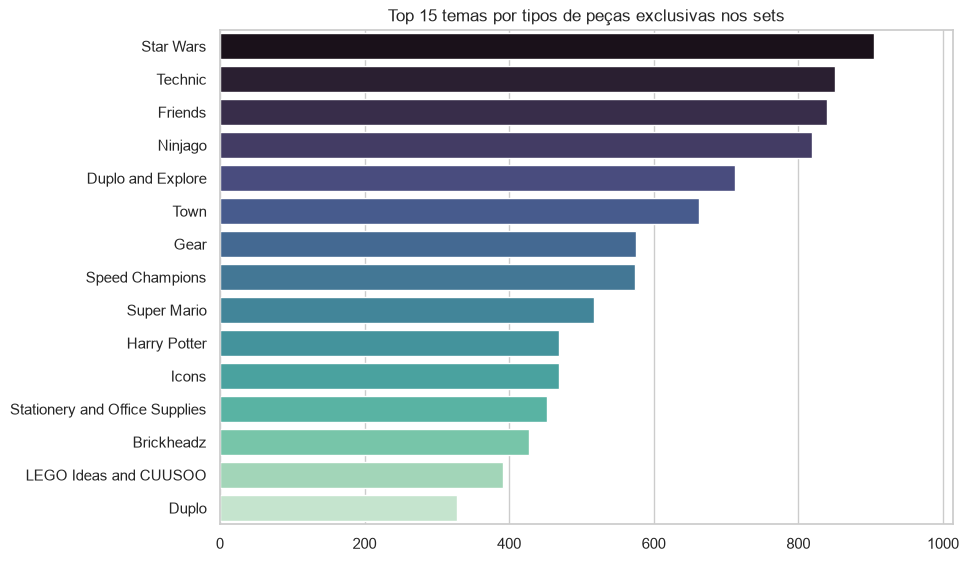

In [12]:
# Considera exclusiva a peça (part_num) que aparece em apenas um set.
parts_by_set = (
    inventory_parts_df
    .join(inventories_df, F.col("inv_p.inventory_id") == F.col("inv.id"), "inner")
    .join(sets_df, F.col("inv.set_num") == F.col("sets.set_num"), "inner")
    .join(themes_df, F.col("sets.theme_id") == F.col("themes.id"), "left")
    .filter(F.coalesce(F.col("themes.name"), F.lit("")) != "Database Sets")
    .select(
        F.col("inv_p.part_num").alias("part_num"),
        F.col("sets.set_num").alias("set_num"),
        F.col("sets.name").alias("set_name"),
        F.coalesce(F.col("themes.name"), F.lit("Tema não identificado")).alias("theme_name"),
    )
    .dropDuplicates(["part_num", "set_num"])
)

parts_set_frequency = parts_by_set.groupBy("part_num").agg(F.count_distinct("set_num").alias("sets_with_part"))

exclusive_parts = (parts_by_set.join(parts_set_frequency.filter(F.col("sets_with_part") == 1).select("part_num"), on="part_num", how="inner"))

exclusive_parts_by_theme = (
    exclusive_parts.groupBy("theme_name")
    .agg(
        F.count_distinct("part_num").alias("exclusive_part_types"),
        F.count_distinct("set_num").alias("sets_with_exclusive_parts"),
    )
)

top_themes_with_exclusive_parts = (
    exclusive_parts_by_theme
    .orderBy(F.desc("exclusive_part_types"), F.asc("theme_name"))
)

top_themes_with_exclusive_parts.show(20, truncate=False)

exclusive_themes_ax = plot_spark(top_themes_with_exclusive_parts.limit(15), kind="bar", x="exclusive_part_types", y="theme_name", hue="theme_name", title="Top 15 temas por tipos de peças exclusivas nos sets")

if exclusive_themes_ax.get_legend() is not None:
    legend = exclusive_themes_ax.get_legend()
    if legend is not None:
        legend.remove()

exclusive_themes_ax.set_xlabel("")
exclusive_themes_ax.set_ylabel("")
exclusive_themes_ax.margins(x=0.12)


Uma coisa é a quantidade de peças exclusivas fornecidas por um tema ao longo do tempo, outra é a proporção da quantidade de peças exclusivas que um tema possui em relação ao seu total de peças. Ou seja, também será interessante analisarmos de um ponto de vista percentual para sabermos quantas peças de um tema ao todo são exclusivas.

[Spark] Temas com maior percentual de tipos de peças exclusivas:
+------------------------------------------+----------------+--------------------+-----------------+
|theme_name                                |total_part_types|exclusive_part_types|exclusive_percent|
+------------------------------------------+----------------+--------------------+-----------------+
|Modulex                                   |49              |49                  |100.0            |
|Posters and Art Prints                    |4               |4                   |100.0            |
|Audio and Visual Media                    |8               |7                   |87.5             |
|Video Games and Accessories               |170             |146                 |85.88            |
|Galidor                                   |104             |81                  |77.88            |
|Gear                                      |784             |576                 |73.47            |
|Formula 1                

(0.0, 100.0)

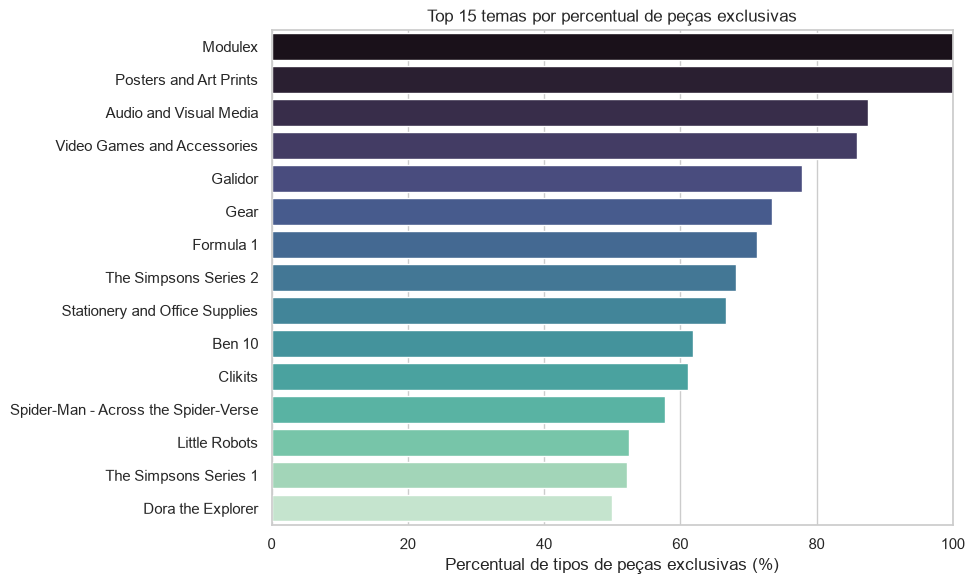

In [14]:
# Calcula  a proporcao de tipos de pecas exclusivas por tema, considerando o total de tipos de peças.
all_parts_by_theme = parts_by_set.groupBy("theme_name").agg(
    F.count_distinct("part_num").alias("total_part_types")
)

exclusive_types_by_theme = exclusive_parts.groupBy("theme_name").agg(
    F.count_distinct("part_num").alias("exclusive_part_types")
)

theme_part_distribution = (
    all_parts_by_theme.join(exclusive_types_by_theme, "theme_name", "left")
    .fillna({"exclusive_part_types": 0})
    .withColumn(
        "exclusive_percent",
        F.round(F.col("exclusive_part_types") / F.col("total_part_types") * 100, 2),
    )
)

top_themes_by_exclusive_percent = theme_part_distribution.orderBy(
    F.desc("exclusive_percent"), F.desc("total_part_types"), F.asc("theme_name")
)

print("[Spark] Temas com maior percentual de tipos de peças exclusivas:")
top_themes_by_exclusive_percent.show(20, truncate=False)

top_theme_percentages = top_themes_by_exclusive_percent.limit(15)
exclusive_percentage_ax = plot_spark(
    top_theme_percentages,
    kind="bar",
    x="exclusive_percent",
    y="theme_name",
    hue="theme_name",
    title="Top 15 temas por percentual de peças exclusivas",
)

if exclusive_percentage_ax.get_legend() is not None:
    legend = exclusive_percentage_ax.get_legend()
    if legend is not None:
        legend.remove()

exclusive_percentage_ax.set_xlabel("Percentual de tipos de peças exclusivas (%)")
exclusive_percentage_ax.set_ylabel("")
exclusive_percentage_ax.set_xlim(0, 100)


Isso comprova que de fato, existem temas de conjuntos que possuem apenas peças exclusivas que não foram reutilizadas em nenhum outro set, e, é interessante notar que mesmo Star Wars tendo a maior quantidade de peças exclusivas em números em nossa última análise, ele não entra nem na lista dos `15` conjuntos de temas com a maior quantidade de peças exclusivas. Enquanto isso, Gear que apareceu em ambas as listas também possui uma incrível proporção de peças exclusivas, sendo ele em nossa concepção o maior tema com partes exclusivas da Lego.

### Público Alvo
Saindo um pouco da questão de temas, conjuntos e peças, nossa última análise tem o objetivo de tentar avaliar a grande maioria do público alvo ao qual a Lego destina seus produtos. Nossa seleção manual não foi feita a partir de nenhum embasamento ou dados oficiais disponibilizados pela Lego, foi uma seleção discutida entre os integrantes para itens que mais fazem sentido serem classificados assim.

É claro para todos que a Lego oferece e disponibiliza seus produtos principalmente para crianças e adolescentes, em sua maioria crianças, apelando aos gostos do público juvenil a cada nova geração de brinquedos. Porém, enquanto que a demanda de Lego vem crescendo exponencialmente ao longo dos anos, a quantidade de pessoas adultas que também colecionam lego como hobby vem aumentando gradualmente. Por isso, fizemos o seguinte questionamento:

**6) O quão grande se tornou a participação do público adulto ao longo dos anos?**

[Spark] 14,030 sets classificados para a análise.
[Spark] Sets excluídos por tema não identificado: 0
[Spark] Sets excluídos por pertencerem às raízes fora do escopo: 3,698
[Spark] Participação dos grupos por período:
+---------+-------------+----------+----------------+
|period   |Grupo        |total_sets|participacao_pct|
+---------+-------------+----------+----------------+
|1990-1999|Adulto       |14        |0.78            |
|1990-1999|Criança      |726       |40.36           |
|1990-1999|Geral/Família|1059      |58.87           |
|2000-2009|Adulto       |246       |7.83            |
|2000-2009|Criança      |1268      |40.34           |
|2000-2009|Geral/Família|1629      |51.83           |
|2010-2019|Adulto       |612       |13.15           |
|2010-2019|Criança      |1497      |32.17           |
|2010-2019|Geral/Família|2545      |54.68           |
|2020-2026|Adulto       |668       |15.07           |
|2020-2026|Criança      |1327      |29.93           |
|2020-2026|Geral/Família|2

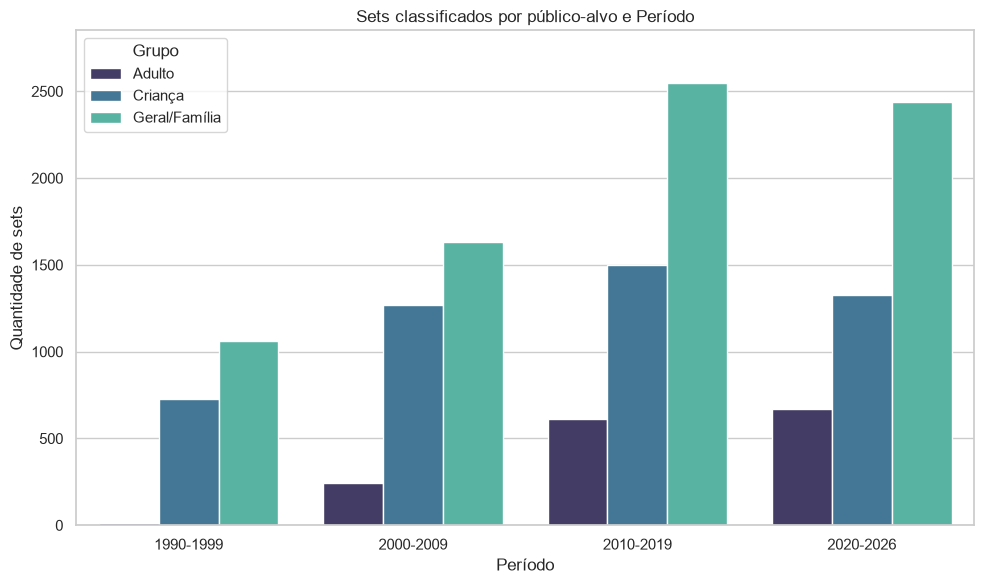

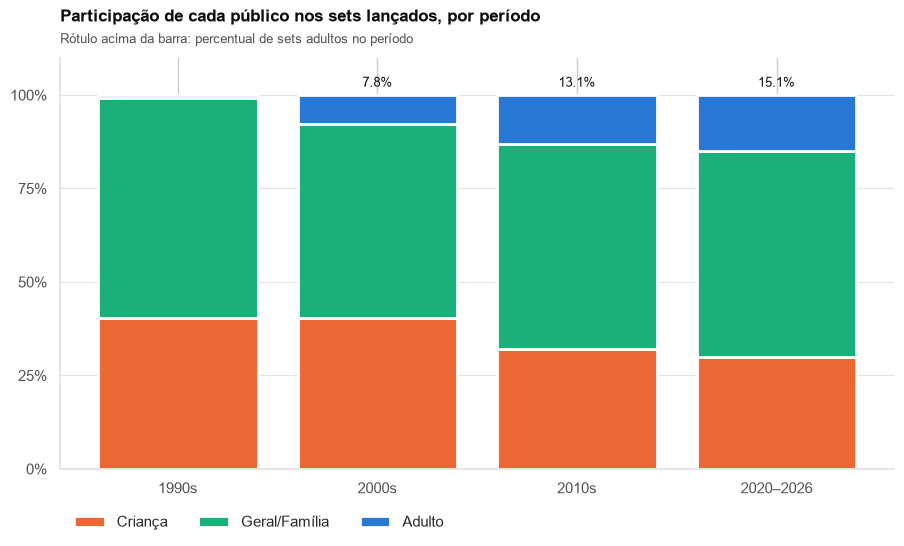

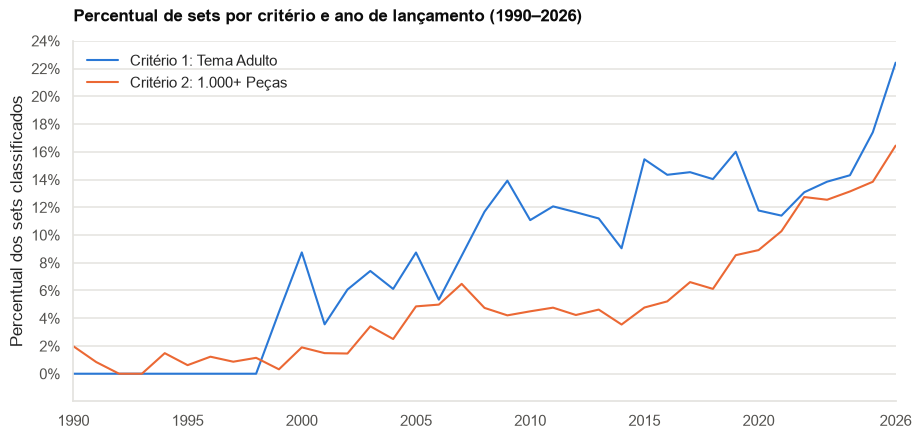

In [20]:
TEMAS_ADULTO = [
    "Icons", "Creator Expert", "Modular Buildings", "Ultimate Collector Series",
    "Architecture", "LEGO Art", "Botanicals", "LEGO Ideas and CUUSOO",
    "Sculptures", "BrickLink Designer Program", "Editions", "Star Wars",
]

TEMAS_CRIANCA = [
    "Duplo", "Primo", "Quatro", "Juniors", "4 Juniors", "Fabuland", "Belville",
    "Friends", "Gabby's Dollhouse", "Bluey", "Dreamzzz", "Scala", "Clikits",
    "Early Creator", "Ninjago", "Star Wars", "Harry Potter", "Unikitty",
    "Bionicle", "Lego City", "Minecraft", "LEGO Super Mario", "Technic",
]

RAIZES_FORA = [
    "Gear", "Books", "Promotional", "Collectible Minifigures", "Service Packs",
    "Bulk Bricks", "Educational and Dacta", "Games", "LEGO Brand Store",
]

theme_count = themes.count()
parent_lookup = themes.select(
    F.col("id").alias("parent_theme_id"),
    F.col("name").alias("ancestor_name"),
    F.col("parent_id").alias("next_parent_id"),
)

frontier = themes.select(
    F.col("id").alias("theme_id"),
    F.col("parent_id").alias("parent_id"),
)

theme_ancestry = themes.select(
    F.col("id").alias("theme_id"),
    F.col("name").alias("ancestor_name"),
    F.col("parent_id").isNull().alias("is_root"),
)

for _ in range(theme_count + 1):
    unresolved = frontier.filter(F.col("parent_id").isNotNull())
    if unresolved.limit(1).count() == 0:
        break

    expanded = unresolved.alias("child").join(
        parent_lookup.alias("parent"),
        F.col("child.parent_id") == F.col("parent.parent_theme_id"),
        "left",
    )

    if expanded.filter(F.col("parent.parent_theme_id").isNull()).limit(1).count():
        raise ValueError("A hierarquia de temas contém um tema pai inexistente.")

    theme_ancestry = theme_ancestry.unionByName(
        expanded.select(
            F.col("child.theme_id").alias("theme_id"),
            F.col("parent.ancestor_name").alias("ancestor_name"),
            F.col("parent.next_parent_id").isNull().alias("is_root"),
        )
    )

    frontier = expanded.select(F.col("child.theme_id").alias("theme_id"), F.col("parent.next_parent_id").alias("parent_id"))
else:
    raise ValueError("A hierarquia de temas contém um ciclo.")

theme_groups = (
    theme_ancestry.groupBy("theme_id")
    .agg(
        F.max(F.when(F.col("ancestor_name").isin(*TEMAS_ADULTO), 1).otherwise(0)).alias("is_adult"),
        F.max(F.when(F.col("ancestor_name").isin(*TEMAS_CRIANCA), 1).otherwise(0)).alias("is_child"),
        F.max(F.when(F.col("is_root"), F.col("ancestor_name"))).alias("root_theme"),
    )
    .withColumn(
        "Grupo",
        F.when(F.col("is_adult") == 1, "Adulto")
        .when(F.col("is_child") == 1, "Criança")
        .when(F.col("root_theme").isin(*RAIZES_FORA), "Fora")
        .otherwise("Geral/Família"),
    )
    .select("theme_id", "Grupo")
)

latest_year_row = sets.agg(F.max("year").alias("latest_year")).first()
if latest_year_row is None or latest_year_row["latest_year"] is None:
    raise ValueError("Não há conjuntos no intervalo de anos analisado.")

latest_year = int(latest_year_row["latest_year"])

sets_with_group = (
    sets.filter(
        F.col("year").between(1990, latest_year) & (F.col("num_parts") > 0)
    )
    .join(theme_groups, "theme_id", "left")
)

unclassified_count = ( sets_with_group.filter(F.col("Grupo").isNull()).select("set_num").distinct().count())
outside_count = (sets_with_group.filter(F.col("Grupo") == "Fora").select("set_num").distinct().count())

period_start = (F.floor((F.col("year") - F.lit(1990)) / F.lit(10)) * F.lit(10) + F.lit(1990))

sets_cls = (
    sets_with_group.filter(F.col("Grupo").isNotNull() & (F.col("Grupo") != "Fora"))
    .withColumn("period_start", period_start.cast("int"))
    .withColumn(
        "period_end",
        F.least(F.col("period_start") + F.lit(9), F.lit(latest_year)),
    )
    .withColumn(
        "period",
        F.concat_ws(
            "-",
            F.col("period_start").cast("string"),
            F.col("period_end").cast("string"),
        ),
    )
    .cache()
)

classified_count = sets_cls.select("set_num").distinct().count()
if classified_count == 0:
    raise ValueError("Nenhum set pôde ser classificado para a análise de público-alvo.")

print(f"[Spark] {classified_count:,} sets classificados para a análise.")
print(f"[Spark] Sets excluídos por tema não identificado: {unclassified_count:,}")
print(f"[Spark] Sets excluídos por pertencerem às raízes fora do escopo: {outside_count:,}")

sets_by_audience_period = (
    sets_cls.groupBy("period_start", "period_end", "period", "Grupo")
    .agg(F.count_distinct("set_num").alias("total_sets"))
)

period_totals = sets_cls.groupBy("period_start", "period_end", "period").agg(F.count_distinct("set_num").alias("period_total_sets"))

audience_share = (
    sets_by_audience_period.join(
        period_totals,
        ["period_start", "period_end", "period"],
    )
    .withColumn(
        "participacao_pct",
        F.col("total_sets") / F.col("period_total_sets") * 100,
    )
    .orderBy("period_start", "Grupo")
)

print("[Spark] Participação dos grupos por período:")
audience_share.select(
    "period", "Grupo", "total_sets",
    F.round("participacao_pct", 2).alias("participacao_pct"),
).show(50, truncate=False)

sets_ax = plot_spark(audience_share, kind="bar", x="period", y="total_sets", hue="Grupo", title="Sets classificados por público-alvo e Período")

sets_ax.set_xlabel("Período")
sets_ax.set_ylabel("Quantidade de sets")
sets_ax.margins(y=0.12)

GRUPOS = ["Criança", "Geral/Família", "Adulto"]

CORES_GRUPO = {
    "Adulto": "#2a78d6",
    "Criança": "#eb6834",
    "Geral/Família": "#1baf7a",
}

TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
GRADE = "#e4e3df"

share_ax = plot_spark(
    audience_share,
    kind="bar",
    x="period",
    y="participacao_pct",
    hue="Grupo",
    stacked=True,
    hue_order=GRUPOS,
    palette=CORES_GRUPO,
)

share_fig = share_ax.figure
share_fig.figure.set_size_inches(9, 4.6)
share_fig.set_facecolor("white")
share_ax.set_facecolor("white")
share_ax.spines[["top", "right"]].set_visible(False)
share_ax.spines[["left", "bottom"]].set_color(GRADE)
share_ax.grid(axis="y", color=GRADE, linewidth=0.8)
share_ax.set_axisbelow(True)
share_ax.tick_params(colors=TINTA_2)
share_ax.set_xlabel("")
share_ax.set_ylabel("")
share_ax.set_ylim(0, 110)
share_ax.set_yticks(range(0, 101, 25), [f"{value}%" for value in range(0, 101, 25)])
share_ax.set_title(
    "Participação de cada público nos sets lançados, por período",
    loc="left",
    pad=26,
    fontsize=12,
    fontweight="bold",
    color=TINTA,
)

period_rows = (
    audience_share.select("period_start", "period_end")
    .distinct()
    .orderBy("period_start")
    .collect()
)
period_labels = [
    f"{row['period_start']}s" if row["period_start"] < 2020
    else f"{row['period_start']}–{row['period_end']}"
    for row in period_rows
]

share_ax.set_xticks(range(len(period_labels)), period_labels)

adult_percentages = {
    row["period_start"]: row["participacao_pct"]
    for row in audience_share.filter(F.col("Grupo") == "Adulto")
    .select("period_start", "participacao_pct")
    .collect()
}

for position, row in enumerate(period_rows):
    percentage = adult_percentages.get(row["period_start"], 0)
    if percentage >= 1:
        share_ax.text(
            position,
            101.5,
            f"{percentage:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9,
            color=TINTA,
        )

share_ax.text(0, 1.035, "Rótulo acima da barra: percentual de sets adultos no período", transform=share_ax.transAxes, fontsize=9, color=TINTA_2)
share_ax.legend(ncols=3, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08))

trend_sets = (
    spark.read.parquet(str(DATA_DIR / "sets.parquet"))
    .filter(F.col("year").between(1990, latest_year) & (F.col("num_parts") > 0))
    .select("set_num", "year", "theme_id", "num_parts")
    .join(theme_groups, "theme_id", "left")
    .filter(F.col("Grupo").isNotNull() & (F.col("Grupo") != "Fora"))
)

yearly_trend = (
    trend_sets.groupBy("year")
    .agg(
        (
            F.avg((F.col("Grupo") == "Adulto").cast("double")) * 100
        ).alias("percent_adult_theme"),
        (
            F.avg((F.col("num_parts") >= 1000).cast("double")) * 100
        ).alias("percent_1000_parts"),
    )
)

TREND_SERIES = [
    "Critério 1: Tema Adulto",
    "Critério 2: 1.000+ Peças",
]

CORES_TREND = {
    TREND_SERIES[0]: CORES_GRUPO["Adulto"],
    TREND_SERIES[1]: CORES_GRUPO["Criança"],
}

trend_adult = yearly_trend.select(
    "year",
    F.lit(TREND_SERIES[0]).alias("criterio"),
    F.col("percent_adult_theme").alias("percentual"),
)

trend_large_sets = yearly_trend.select(
    "year",
    F.lit(TREND_SERIES[1]).alias("criterio"),
   
    F.col("percent_1000_parts").alias("percentual"),
)
trend_plot_data = trend_adult.unionByName(trend_large_sets).orderBy("year", "criterio")

trend_ax = plot_spark(
    trend_plot_data,
    kind="line",
    x="year",
    y="percentual",
    hue="criterio",
    hue_order=TREND_SERIES,
    palette=CORES_TREND,
    title=f"",
)

trend_fig = trend_ax.figure
trend_fig.figure.set_size_inches(9, 4.2)
trend_fig.set_facecolor("white")
trend_ax.set_facecolor("white")
trend_ax.spines[["top", "right"]].set_visible(False)
trend_ax.spines[["left", "bottom"]].set_color(GRADE)

trend_ax.grid(False, axis="x")
trend_ax.grid(axis="y", color=GRADE, linewidth=1.1)

trend_ax.set_axisbelow(True)
trend_ax.tick_params(colors=TINTA_2)

trend_ax.set_xlim(1990, latest_year)

year_ticks = list(range(1990, latest_year + 1, 5))
if latest_year not in year_ticks:
    if latest_year - year_ticks[-1] <= 2:
        year_ticks[-1] = latest_year
    else:
        year_ticks.append(latest_year)

trend_ax.set_xticks(year_ticks)

trend_ax.set_ylim(-2, 24)
trend_ax.set_yticks(range(0, 25, 2), [f"{value}%" for value in range(0, 25, 2)])

trend_ax.set_xlabel("")
trend_ax.set_ylabel("Percentual dos sets classificados")
trend_ax.set_title(
    f"Percentual de sets por critério e ano de lançamento (1990–{latest_year})",
    loc="left",
    pad=14,
    fontsize=12,
    fontweight="bold",
    color=TINTA,
)

trend_ax.legend(frameon=False, loc="upper left")


Os dois primeiros gráficos apresentam a tendência geral dos focos da Lego na distribuição de seus conjuntos, datando o período inicial de 1990 até 2009, o seu foco atingia apenas majoritariamente famílias e/ou crianças, com temas que seguiam as maiores tendências pra época e que eram apelativos ao público infantil. Partes e brinquedos coloridos, personagens famosos de mídias de desenhos e afins eram os mais atrativos para as crianças, enquanto que conjuntos grandes como Lego City, cidades, construções, qualquer projeto um pouco mais amplo era destinado a familia ao todo. É possível facilmente apontar de maneira precisa qual era o público alvo da Lego nessa época, o anúncio abaixo apresenta uma família montando um de seus famosos conjuntos de arquitetura, exibido por volta dos anos 80.

![Anuncio](https://image.adsoftheworld.com/k1xj3nl6m0x8ytr0uha00lehk6yv)

Porém, isso não quer dizer que os brinquedos e os conjuntos de Lego também não tenham sido um atrativo para os adultos, tanto nos dois primeiros gráficos como no último gráfico podemos acompanhar uma tendência evolutiva na criação de temas e conjuntos que não só atendem tanto às crianças e famílias num geral, como que também atraiam especificamente adultos que visavam colecioná-los. O maior pontapé dado nessa direção foi a produção do primeiro conjunto de Star Wars, atraíndo uma montanha de fãs ávidos também a colecionar e montar os conjuntos desse tema.

É por isso que podemos observar um salto nessa tendência por volta dos anos 2000, em termos proporcionais, a participação dos sets adultos passou de aproximadamente `7,8%` nos anos 2000 para `13,1%` na década de 2010, demonstrando um dos seus maiores ápices evolutivos, fechando com 15,1% entre 2020 e 2026. Vale-se dizer que esse valores representam a participação total dos sets adultos **lançados** durante cada período, e não sua participação geral acumulada da Lego. O crescimento sugere uma mudança gradual na composição dos lançamentos, embora que, claramente os conjuntos de família continuam representando a maior parcela do catálogo anual de novos lançamentos.

A evolução anual também reforça essa tendência, principalmente nos anos mais recentes que vemos uma perda no estigma acerca de colecionadores de legos, e uma vasta onda de ampliação na prática de hobbies por diversas pessoas. Em 2026, aproximadamente `22,5%` dos sets classificados pertencem a temas adultos, enquanto `16,5%` desses sets possuem mais de 1.000 peças em seus conjuntos. Para ambos os indicadores, a base percentual corresponde ao total de sets classificados lançados a cada ano, considerando apenas registros como quantidade de peças válidas. As porcentagens por período foram calculadas considerando a quantidade de sets de cada grupo dividida pelo total de sets classificados naquele mesmo período, excluindo conjuntos sem classificação válida.

## Considerações Finais
Com essa última análise encerramos a exploração dos dados de sets LEGO, aqui pudemos observar e questionar sobre algumas curiosidades das práticas estabelecidas pela empresa Lego, assim como algumas análises de mercado em relação a tendências que eram seguidas por período, e o público alvo ao qual destinavam majoritariamente a distribuição e criação de novos conjuntos e temas.

De modo geral, as análises permitiram identificar padrões, tendências e diferenças na composição da análise de cada questionamento, oferecendo uma visão mais ampla sobre a evolução do catálogo da LEGO e algumas mudanças de estratégias que eles teriam realizado durante cada período. Embora os resultados estejam limitados aos registros disponíveis na base de dados, eles fornecem informações relevantes sobre as transformações observadas pelo tempo estudado.

Assim, concluímos essa etapa de análise exploratória, reunindo os principais resultados obtidos a partir dos dados disponíveis e de todas as perguntas fomentadas durante uma sessão de brainstorming geral entre os integrantes do grupo.